#**Phase 1: Step 1 - Data Exploration & Understanding**


In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv("/content/Ad_click_prediction_train (1).csv")

Checking Dimensions

In [ ]:
print(df.shape)

(463291, 15)


In [ ]:
info_df = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique()
})

In [ ]:
info_df

,Data Type,Missing Values,Unique Values
session_id,int64,0,463291
DateTime,object,0,8610
user_id,int64,0,150347
product,object,0,10
campaign_id,int64,0,10
webpage_id,int64,0,9
product_category_1,int64,0,5
product_category_2,float64,365854,29
user_group_id,float64,18243,13
gender,object,18243,2


Target Variable analysis

In [ ]:
target_col = 'is_click'

In [ ]:
click_counts = df[target_col].value_counts()

In [ ]:
ctr = df[target_col].mean() * 100

In [ ]:
print(f"Total Non-Clicks (0): {click_counts.get(0, 0)}")
print(f"Total Clicks (1): {click_counts.get(1, 0)}")
print(f"Base Click-Through Rate (CTR): {ctr:.2f}%")

Total Non-Clicks (0): 431960
Total Clicks (1): 31331
Base Click-Through Rate (CTR): 6.76%


Missing values % in each column

In [ ]:
missing_val = (info_df['Missing Values']/len(df))*100

In [ ]:
missing_val

,Missing Values
session_id,0.000000
DateTime,0.000000
user_id,0.000000
product,0.000000
campaign_id,0.000000
webpage_id,0.000000
product_category_1,0.000000
product_category_2,78.968510
user_group_id,3.937698
gender,3.937698


### Key Observations - Initial Data Inspection
- **Total Records:** 463,291 rows
- **Class Imbalance:** Highly imbalanced with only **6.76% Clicks (1)** vs **93.24% Non-Clicks (0)**.
- **Business Implication:** Model optimized for pure accuracy will default to predicting 0. Focus must be on **AUC-ROC**, **Precision-Recall**, and techniques like **SMOTE / Class Weighting**.

#**Phase 1: Step 2 - Exploratory Data Analysis (EDA)**

In [ ]:
print(f"Non-Click Rate: {100 - ctr:.2f}%")
print(f"Imbalance Ratio: Approx 1 Click for every {int((1-df['is_click'].mean())/df['is_click'].mean())} Non-Clicks\n")

Non-Click Rate: 93.24%
Imbalance Ratio: Approx 1 Click for every 13 Non-Clicks



Temporal Patterns (Hours, Weekdays/Weekends)

In [ ]:
time_col = 'DateTime'
if time_col in df.columns:
    df[time_col] = pd.to_datetime(df[time_col])
    df['Hour'] = df[time_col].dt.hour
    df['day_of_week'] = df[time_col].dt.dayofweek
    df['is_weekend'] = df['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)

    weekend_ctr = df.groupby('is_weekend')['is_click'].mean() * 100
    print(f"Weekday CTR: {weekend_ctr.get(0, 0):.2f}%")
    print(f"Weekend CTR: {weekend_ctr.get(1, 0):.2f}%\n")

if 'DateTime' in df.columns:
    df['Month'] = df['DateTime'].dt.month_name()
    monthly_ctr = df.groupby('Month')['is_click'].agg(
            Impressions = 'count',
            Clicks = 'sum',
            CTR_Pct = lambda x: x.mean()*100
    ).sort_values(by='CTR_Pct', ascending=False)
    print(monthly_ctr)


Weekday CTR: 6.65%
Weekend CTR: 7.33%

       Impressions  Clicks   CTR_Pct
Month                               
July        463291   31331  6.762704


HOURLY PATTERNS

In [ ]:
hourly_ctr = df.groupby('Hour')['is_click'].agg(['count', 'mean'])
hourly_ctr['mean'] = hourly_ctr['mean'] * 100
print("--- Peak Clicks by Hour ---")
print(f"Peak Hour: {hourly_ctr['mean'].idxmax()}:00 with CTR: {hourly_ctr['mean'].max():.2f}%")
print(f"Lowest Hour: {hourly_ctr['mean'].idxmin()}:00 with CTR: {hourly_ctr['mean'].min():.2f}%\n")

--- Peak Clicks by Hour ---
Peak Hour: 1:00 with CTR: 7.46%
Lowest Hour: 2:00 with CTR: 5.27%



PRODUCT CTR

In [ ]:
product_ctr = df.groupby('product')['is_click'].agg(
    Impressions = 'count',
    Clicks = 'sum',
    CTR_Pct = lambda x: x.mean()*100
).sort_values(by='CTR_Pct', ascending=False)

print(product_ctr)

         Impressions  Clicks   CTR_Pct
product                               
J               9698     899  9.269953
D              41064    2949  7.181473
H             109574    7654  6.985234
C             163501   11306  6.914942
E              21452    1474  6.871154
I              63711    4079  6.402348
A              15391     953  6.191930
B              22479    1238  5.507362
F               7007     344  4.909376
G               9414     435  4.620778


WEBPAGE & CAMPAIGN PERFORMANCE

In [ ]:
webpage_ctr = df.groupby('webpage_id')['is_click'].agg(
    Impressions = 'count',
    Clicks = 'sum',
    CTR_Pct = lambda x: x.mean()*100
).sort_values(by='CTR_Pct', ascending=False)

campaign_ctr = df.groupby('campaign_id')['is_click'].agg(
    Impressions = 'count',
    Clicks = 'sum',
    CTR_Pct = lambda x: x.mean()*100
).sort_values(by='CTR_Pct', ascending=False)

print(webpage_ctr)
print(campaign_ctr)

            Impressions  Clicks   CTR_Pct
webpage_id                               
60305             95973    8763  9.130693
53587             28826    2235  7.753417
6970              35065    2694  7.682875
51181             24909    1809  7.262435
11085             25781    1762  6.834491
1734              27849    1776  6.377249
45962             29314    1710  5.833390
13787            160043    8686  5.427291
28529             35531    1896  5.336185
             Impressions  Clicks   CTR_Pct
campaign_id                               
405490             95973    8763  9.130693
404347             28826    2235  7.753417
98970              35065    2694  7.682875
396664             24909    1809  7.262435
105960             25781    1762  6.834491
82320              27849    1776  6.377249
359520            108155    6340  5.861957
414149             29314    1710  5.833390
118601             35531    1896  5.336185
360936             51888    2346  4.521277


USER DEMOGRAPHICS

In [ ]:
if 'gender' in df.columns:
  gender_ctr = df.groupby('gender')['is_click'].agg(
      Impressions = 'count',
      Clicks = 'sum',
      CTR_Pct = lambda x: x.mean()*100
  ).sort_values(by='CTR_Pct', ascending=False)


if 'age_level' in df.columns:
  age_ctr = df.groupby('age_level')['is_click'].agg(
      Impressions = 'count',
      Clicks = 'sum',
      CTR_Pct = lambda x: x.mean()*100
  ).sort_values(by='CTR_Pct', ascending=False)


if 'user_group_id' in df.columns:
  user_group_ctr = df.groupby('user_group_id')['is_click'].agg(
      Impressions = 'count',
      Clicks = 'sum',
      CTR_Pct = lambda x: x.mean()*100
  ).sort_values(by='CTR_Pct', ascending=False)

print(gender_ctr)
print(age_ctr)
print(user_group_ctr)

        Impressions  Clicks   CTR_Pct
gender                               
Male         393454   26732  6.794187
Female        51594    3325  6.444548
           Impressions  Clicks   CTR_Pct
age_level                               
0.0                153      13  8.496732
6.0               2759     227  8.227619
1.0              43367    3244  7.480342
5.0              30828    2286  7.415337
2.0             143501   10177  7.091937
3.0             160581   10360  6.451573
4.0              63859    3750  5.872312
               Impressions  Clicks   CTR_Pct
user_group_id                               
12.0                  1035      92  8.888889
0.0                    153      13  8.496732
6.0                   1724     135  7.830626
11.0                  8839     678  7.670551
1.0                  41946    3152  7.514423
5.0                  21989    1608  7.312747
2.0                 137278    9780  7.124230
7.0                   1421      92  6.474314
3.0                 140317   

Phase 1: Data Exploration & Understanding (Key Insights Summary)

---

## 1. Target Variable & Data Imbalance
* **Overall Click-Through Rate (CTR):** **6.76%** (31,331 clicks out of 463,291 total ad impressions).
* **Class Imbalance:** The dataset is severely imbalanced with a ~14:1 ratio of non-clicks (93.24%) to clicks (6.76%).
* **Modeling Strategy:** Standard accuracy metrics will be misleading (predicting all 0s gives ~93% accuracy). Model evaluation must focus on **AUC-ROC**, **Precision-Recall**, and **F1-Score**. Resampling techniques like **SMOTE** or algorithmic adjustments like **Class Weighting** (`scale_pos_weight`) are required to minimize False Negatives.

---

## 2. Temporal & Seasonality Patterns
* **Weekday vs. Weekend:** Weekend CTR (**7.33%**) outperforms Weekday CTR (**6.65%**), indicating higher user engagement and conversion propensity during non-working days.
* **Hourly Dynamics:** Clicks peak at **1:00 AM** (CTR: **7.46%**), while the lowest engagement occurs at **2:00 AM** (CTR: **5.27%**). Late-night browsing shows higher click responsiveness.
* **Monthly Granularity:** The provided dataset spans exclusively across **July** (463,291 records). Intra-year seasonality cannot be modeled, shifting focus to weekly and hourly temporal dynamics.

---

## 3. User Behavior & Demographics
* **High-Converting Age Groups:** Age levels `0.0` (CTR: **8.50%**) and `6.0` (CTR: **8.23%**) exhibit significantly higher click propensity compared to mid-range age levels like `4.0` (CTR: **5.87%**).
* **Gender Breakdown:** Male users generate the majority of impressions (393,454) with a CTR of **6.79%**, slightly outperforming Female users (**6.44%** CTR across 51,594 impressions).
* **User Group Impact:** `user_group_id` **12.0** (CTR: **8.89%**) and **0.0** (CTR: **8.50%**) are top-performing segments. Conversely, group `10.0` shows the lowest response rate (**5.65%**).

---

## 4. Inventory, Campaign & Webpage Drivers
* **Product Performance:** Product **J** is the standout top performer with a **9.27%** CTR (899 clicks / 9,698 impressions). Products **G** (**4.62%**) and **F** (**4.91%**) underperform significantly.
* **Campaign & Placement Alignment:** Campaign **405490** and Webpage **60305** deliver the highest conversion efficiency, both driving a **9.13%** CTR.

---

## 5. Strategic Recommendations for Modeling (Phase 2 Roadmap)
1. **Handling Null Values:** Categorical features with missing values (e.g., `product_category_2` with ~79% nulls) will be treated by assigning an explicit `'Unknown'` / `-1` category rather than mean/mode imputation.
2. **Feature Engineering Focus:** Create high-signal interaction features like `user_product_count`, `user_total_sessions`, and target-encoded historical CTRs (`product_hist_ctr`, `webpage_hist_ctr`).
3. **Bidding Strategy Adjustment:** Higher bid multipliers should be allocated for weekend placements, peak night hours (1:00 AM), Product `J`, and User Groups `12.0` & `0.0`.

#**Phase 2: Step 1 - DateTime Feature Extraction**

In [ ]:
df_fe = df.copy()

In [ ]:
time_col = 'DateTime'
df_fe[time_col] = pd.to_datetime(df_fe[time_col])

Basic Calendar & Time Features

In [ ]:
df_fe['hour'] = df_fe[time_col].dt.hour
df_fe['day_of_week'] = df_fe[time_col].dt.dayofweek
df_fe['day_of_month'] = df_fe[time_col].dt.day
df_fe['month'] = df_fe[time_col].dt.month
df_fe['is_weekend'] = df_fe['day_of_week'].isin([5, 6]).astype(int)
df_fe['time_of_day'] = df_fe[time_col].dt.hour

Categorical 'time_of_day' Binner (Logical Night, Morning, Afternoon, Evening)

In [ ]:
def assign_time_of_day(hour):
    if 0 <= hour < 6:
      return 'night'
    elif 6 <= hour < 12:
      return 'morning'
    elif 12<= hour < 17:
      return "afternoon"
    elif 17 <= hour < 21:
      return "evening"
    else:
      return "night"


df_fe['time_of_day'] = df_fe['time_of_day'].apply(assign_time_of_day)

Verification & Summary Output

In [ ]:
extracted_time_cols = ['hour', 'day_of_week', 'day_of_month', 'month', 'is_weekend', 'time_of_day']

In [ ]:
print("DateTime Features Successfully Extracted!\n")
print("--- Sample Records with New DateTime Features ---")
print(df_fe[[time_col] + extracted_time_cols].head())

DateTime Features Successfully Extracted!

--- Sample Records with New DateTime Features ---
             DateTime  hour  day_of_week  day_of_month  month  is_weekend  \
0 2017-07-02 00:00:00     0            6             2      7           1   
1 2017-07-02 00:00:00     0            6             2      7           1   
2 2017-07-02 00:00:00     0            6             2      7           1   
3 2017-07-02 00:00:00     0            6             2      7           1   
4 2017-07-02 00:01:00     0            6             2      7           1   

  time_of_day  
0       night  
1       night  
2       night  
3       night  
4       night  


In [ ]:
print("\n--- Distribution of Newly Created 'time_of_day' Feature ---")
print(df_fe['time_of_day'].value_counts())


--- Distribution of Newly Created 'time_of_day' Feature ---
time_of_day
morning      153680
afternoon    121171
evening      118419
night         70021
Name: count, dtype: int64


In [ ]:
print("\n--- CTR Breakdown across 'time_of_day' (%) ---")
tod_ctr = df_fe.groupby('time_of_day')['is_click'].agg(
    Impressions='count',
    Clicks='sum',
    CTR_Pct=lambda x: x.mean() * 100
).sort_values(by='CTR_Pct', ascending=False)
print(tod_ctr)


--- CTR Breakdown across 'time_of_day' (%) ---
             Impressions  Clicks   CTR_Pct
time_of_day                               
morning           153680   10842  7.054919
evening           118419    7865  6.641671
afternoon         121171    8032  6.628649
night              70021    4592  6.558033


Phase 2 - Step 1: DateTime Feature Extraction Rationale

1. **Granular Temporal Signals:**
   - `hour` and `day_of_week` capture high-frequency cyclical behavior (e.g., peak click activity late night vs office hours).
   - `is_weekend` allows tree models to make explicit binary splits on weekday/weekend user intent.

2. **Categorical Binning (`time_of_day`):**
   - Grouping hours into `morning` (6-12), `afternoon` (12-17), `evening` (17-21), and `night` (21-6) reduces temporal noise and helps non-tree linear baselines generalize better.

3. **Monthly & Daily Pay-Cycle Dynamics:**
   - `day_of_month` captures end-of-month / start-of-month purchasing propensity and budget allocations.

#**Phase 2: Step 2 - Interaction Features (Combined / Cross Features)**

gender_age Interaction Feature (Demographics Micro-Segment)

In [ ]:
df_fe['gender_age'] = df_fe['gender'].astype(str) + "_" + df_fe['age_level'].astype(str)

campaign_webpage Interaction Feature (Placement Dynamics)

In [ ]:
df_fe['campaign_webpage'] = df_fe['campaign_id'].astype(str) + "_" + df_fe['webpage_id'].astype(str)

user_product_interaction Feature & Interaction Frequency Count

In [ ]:
df_fe['user_product_interaction'] = df_fe['user_id'].astype(str) + "_" + df_fe['product'].astype(str)

Extra Value Feature: How many times has this specific user interacted with this specific product?

In [ ]:
df_fe['user_product_count'] = df_fe.groupby(['user_id', 'product'])['session_id'].transform('count')

Verification & Interaction Performance Check

In [ ]:
print("--- 1. Top Performing Demographics Micro-Segments (gender_age CTR) ---")
gender_age_ctr = df_fe.groupby('gender_age')['is_click'].agg(
    Impressions='count',
    Clicks='sum',
    CTR_Pct=lambda x: x.mean() * 100
).sort_values(by='CTR_Pct', ascending=False)
print(gender_age_ctr.head(7))



print("--- 2. Top Performing Campaign + Webpage Placements (campaign_webpage CTR) ---")
camp_web_ctr = df_fe.groupby('campaign_webpage')['is_click'].agg(
    Impressions='count',
    Clicks='sum',
    CTR_Pct=lambda x: x.mean() * 100
).sort_values(by='CTR_Pct', ascending=False)
print(camp_web_ctr.head(7))


print("--- 3. CTR by User-Product Repeat Exposure Count ---")
up_count_ctr = df_fe.groupby('user_product_count')['is_click'].agg(
    Impressions='count',
    Clicks='sum',
    CTR_Pct=lambda x: x.mean() * 100
).reset_index()
print(up_count_ctr.head(10).to_string(index=False))

print("--- 2. Sample Top-Converting Specific User-Product Pairs ---")
up_pair_ctr = df_fe.groupby('user_product_interaction')['is_click'].agg(
    Impressions='count',
    Clicks='sum',
    CTR_Pct=lambda x: x.mean() * 100
)
# Filter pair with at least 5 impressions to remove 1-shot noise
high_volume_pairs = up_pair_ctr[up_pair_ctr['Impressions'] >= 5].sort_values(by='CTR_Pct', ascending=False)
print(high_volume_pairs.head(10))

--- 1. Top Performing Demographics Micro-Segments (gender_age CTR) ---
            Impressions  Clicks    CTR_Pct
gender_age                                
Male_0.0            120      12  10.000000
Female_6.0         1035      92   8.888889
Male_6.0           1724     135   7.830626
Female_5.0         8839     678   7.670551
Male_1.0          41946    3152   7.514423
Male_5.0          21989    1608   7.312747
Male_2.0         137278    9780   7.124230
--- 2. Top Performing Campaign + Webpage Placements (campaign_webpage CTR) ---
                  Impressions  Clicks   CTR_Pct
campaign_webpage                               
405490_60305            95973    8763  9.130693
404347_53587            28826    2235  7.753417
98970_6970              35065    2694  7.682875
396664_51181            24909    1809  7.262435
105960_11085            25781    1762  6.834491
82320_1734              27849    1776  6.377249
359520_13787           108155    6340  5.861957
--- 3. CTR by User-Product Repe

#**Phase 2: Step 3 - Aggregated Features**

USER-LEVEL AGGREGATIONS

In [ ]:
#User total views (impressions)
df_fe['user_total_views'] = df_fe.groupby('user_id')['session_id'].transform('count')

In [ ]:
# User total clicks
df_fe['user_total_clicks'] = df_fe.groupby('user_id')['is_click'].transform('sum')

In [ ]:
# User's personal CTR
df_fe['user_ctr'] = df_fe['user_total_clicks'] / df_fe['user_total_views']

In [ ]:
#User unique sessions
df_fe['user_sessions'] = df_fe.groupby('user_id')['session_id'].transform('nunique')

PRODUCT-LEVEL AGGREGATIONS

In [ ]:
# Product total views (impressions)
df_fe['product_views'] = df_fe.groupby('product')['session_id'].transform('count')

In [ ]:
# Product historical CTR
product_clicks = df_fe.groupby('product')['is_click'].transform('sum')
df_fe['product_ctr'] = product_clicks / df_fe['product_views']

CAMPAIGN-LEVEL AGGREGATIONS

In [ ]:
# Campaign total views
df_fe['campaign_views'] = df_fe.groupby('campaign_id')['session_id'].transform('count')

In [ ]:
# Campaign historical CTR
campaign_clicks = df_fe.groupby('campaign_id')['is_click'].transform('sum')
df_fe['campaign_ctr'] = campaign_clicks / df_fe['campaign_views']

Verification & Inspection

In [ ]:
agg_cols = [
    'user_total_views', 'user_total_clicks', 'user_ctr', 'user_sessions',
    'product_views', 'product_ctr',
    'campaign_views', 'campaign_ctr'
]

print("Aggregated Features Successfully Calculated!\n")
print("--- Sample Records of Newly Created Aggregated Features ---")
print(df_fe[['user_id', 'product', 'campaign_id'] + agg_cols].head())

Aggregated Features Successfully Calculated!

--- Sample Records of Newly Created Aggregated Features ---
   user_id product  campaign_id  user_total_views  user_total_clicks  \
0   858557       C       359520                 2                  0   
1   243253       C       105960                 3                  0   
2   243253       C       359520                 3                  0   
3  1097446       I       359520                18                  0   
4   663656       C       405490                11                  2   

   user_ctr  user_sessions  product_views  product_ctr  campaign_views  \
0  0.000000              2         163501     0.069149          108155   
1  0.000000              3         163501     0.069149           25781   
2  0.000000              3         163501     0.069149          108155   
3  0.000000             18          63711     0.064023          108155   
4  0.181818             11         163501     0.069149           95973   

   campaign_ctr 

Phase 2 - Step 3: Aggregated Features Rationale

1. **User Historical Engagement Signal:**
   - Features like `user_ctr` and `user_total_views` capture baseline user intent—distinguishing passive scrollers from active clickers.

2. **Inventory & Campaign Attractiveness:**
   - `product_ctr` and `campaign_ctr` act as powerful Bayesian priors for the model, summarizing global creative and product quality in a single numerical feature.

3. **Data Leakage & Production Note:**
   - Since feature exploration is conducted on the single available dataset, global aggregations represent baseline historical features.
   - In a production real-time ad serving pipeline, these target-based aggregations would be computed strictly on historical time-windows (e.g., rolling 7-day or 30-day CTR) or using Out-of-Fold (OOF) target encoding to prevent data leakage onto unseen inference requests.

#**Phase 3: Data Preprocessing: Step 1 - Handle Missing Values**

In [ ]:
df_prep = df_fe.copy()

In [ ]:
null_counts = df_prep.isnull().sum()
print(null_counts[null_counts >0])

product_category_2        365854
user_group_id              18243
gender                     18243
age_level                  18243
user_depth                 18243
city_development_index    125129
dtype: int64


CATEGORICAL COLUMNS IMPUTATION (Mode for strings)

In [ ]:
categorical_cols = df_prep.select_dtypes(include=['object', 'category']).columns.tolist()

In [ ]:
for col in categorical_cols:
    if df_prep[col].isnull().sum() > 0:
        mode_val = df_prep[col].mode()[0]

print(f"Categorical '{col}' Imputed (Missing count was {null_counts[col]})")

Categorical 'user_product_interaction' Imputed (Missing count was 0)


NUMERICAL COLUMNS IMPUTATION (Median - Robust to outliers)

In [ ]:
numerical_cols = df_prep.select_dtypes(include=['int64', 'float64']).columns.tolist()
# Remove target and session IDs from numerical list if present
numerical_cols = [c for c in numerical_cols if c not in ['is_click', 'session_id', 'user_id']]

for col in numerical_cols:
    if df_prep[col].isnull().sum() > 0:
        median_val = df_prep[col].median()
        df_prep[col] = df_prep[col].fillna(median_val)
        print(f"Numerical '{col}' Imputed with Median ({median_val})")

Numerical 'product_category_2' Imputed with Median (146115.0)
Numerical 'user_group_id' Imputed with Median (3.0)
Numerical 'age_level' Imputed with Median (3.0)
Numerical 'user_depth' Imputed with Median (3.0)
Numerical 'city_development_index' Imputed with Median (2.0)


Verification

In [ ]:
remaining_nulls = df_prep.isnull().sum().sum()
print(f"\nTotal Missing Values Remaining in Dataset: {remaining_nulls}")


Total Missing Values Remaining in Dataset: 18243


#**Phase 3 - Step 2: Encode categorical variables (label encoding)**

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
df_encoded = df_prep.copy()

In [ ]:
cols_to_encode = [
    'product',
    'campaign_id',
    'webpage_id',
    'product_category_1',
    'product_category_2',
    'gender',
    'user_group_id',
    'var_1',
    'gender_age',
    'campaign_webpage',
    'user_product_interaction',
    'user_product_count'
]

Dictionary to store fitted LabelEncoders

In [ ]:
label_encoders = {}

In [ ]:
for col in cols_to_encode:
    if col in df_encoded.columns:
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
        label_encoders[col] = le
        print(f"Encoded '{col}': {len(le.classes_)} categories mapped successfully.")
    else:
        print(f"Column '{col}' not found in DataFrame.")

Encoded 'product': 10 categories mapped successfully.
Encoded 'campaign_id': 10 categories mapped successfully.
Encoded 'webpage_id': 9 categories mapped successfully.
Encoded 'product_category_1': 5 categories mapped successfully.
Encoded 'product_category_2': 29 categories mapped successfully.
Encoded 'gender': 3 categories mapped successfully.
Encoded 'user_group_id': 13 categories mapped successfully.
Encoded 'var_1': 2 categories mapped successfully.
Encoded 'gender_age': 15 categories mapped successfully.
Encoded 'campaign_webpage': 10 categories mapped successfully.
Encoded 'user_product_interaction': 245846 categories mapped successfully.
Encoded 'user_product_count': 73 categories mapped successfully.


Verify that all object/categorical columns are now converted to numerical

In [ ]:
remaining_columns = df_encoded.select_dtypes(include=['object','category']).columns.tolist()

In [ ]:
print(f"Remaining categorical columns: {remaining_columns}")

Remaining categorical columns: ['Month', 'time_of_day']


#**PHASE 3 - STEP 3: FEATURE SELECTION & FINAL FEATURE SET CREATION**

In [ ]:
drop_cols = ['DateTime', 'session_id', 'user_id', 'Month', 'time_of_day']

In [ ]:
actual_drop_cols = [c for c in drop_cols if c in df_encoded.columns]

In [ ]:
df_final = df_encoded.drop(columns = actual_drop_cols)
print("--- Feature Selection Summary ---")
print(f"Dropped High Cardinality / Redundant Columns: {actual_drop_cols}")
print(f"Total Initial Features: {df_encoded.shape[1]}")
print(f"Total Selected Features: {df_final.shape[1] - 1} (excluding target 'is_click')")
print(f"Final Dataset Shape: {df_final.shape}\n")

--- Feature Selection Summary ---
Dropped High Cardinality / Redundant Columns: ['DateTime', 'session_id', 'user_id', 'Month', 'time_of_day']
Total Initial Features: 35
Total Selected Features: 29 (excluding target 'is_click')
Final Dataset Shape: (463291, 30)



#**PHASE 3 - STEP 4: TRAIN-VALIDATION / TEST SPLIT & SCALING**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
test_df = pd.read_csv('/content/Ad_Click_prediciton_test.csv')
print(f"Test Shape: {test_df.shape}")


Test Shape: (128858, 14)


In [ ]:
test_df.columns

Index(['session_id', 'DateTime', 'user_id', 'product', 'campaign_id',
       'webpage_id', 'product_category_1', 'product_category_2',
       'user_group_id', 'gender', 'age_level', 'user_depth',
       'city_development_index', 'var_1'],
      dtype='object')

In [ ]:
df_train_temp = df.copy()
df_test_temp = test_df.copy()

df_train_temp['is_test_flag'] = 0
df_test_temp['is_test_flag'] = 1

# Combine Train & Test
combined = pd.concat([df_train_temp, df_test_temp], axis=0, ignore_index=True)

# 2. Date & Time Features
time_col = 'DateTime' if 'DateTime' in combined.columns else 'timestamp'
combined[time_col] = pd.to_datetime(combined[time_col])

combined['hour'] = combined[time_col].dt.hour
combined['day_of_week'] = combined[time_col].dt.dayofweek
combined['is_weekend'] = combined['day_of_week'].isin([5, 6]).astype(int)

# 3. Interaction Features
combined['gender_age'] = combined['gender'].astype(str) + "_" + combined['age_level'].astype(str)
combined['campaign_webpage'] = combined['campaign_id'].astype(str) + "_" + combined['webpage_id'].astype(str)
combined['user_product_interaction'] = combined['user_id'].astype(str) + "_" + combined['product'].astype(str)
combined['user_product_count'] = combined.groupby('user_id')['product'].transform('count')

# 4. Handle Missing Values
cat_missing_cols = ['product_category_2', 'user_group_id', 'gender', 'age_level', 'user_depth', 'city_development_index']
for col in cat_missing_cols:
    if col in combined.columns:
        combined[col] = combined[col].fillna(-1)

# 5. Categorical Encoding (Label Encoding on Full Set)
cols_to_encode = ['product', 'campaign_id', 'webpage_id', 'product_category_1',
                  'product_category_2', 'gender', 'user_group_id', 'var_1',
                  'gender_age', 'campaign_webpage', 'user_product_interaction']

for col in cols_to_encode:
    if col in combined.columns:
        le = LabelEncoder()
        combined[col] = le.fit_transform(combined[col].astype(str))

# 6. Drop Raw / Redundant Identifiers
drop_cols = [time_col, 'session_id', 'user_id', 'Month', 'time_of_day']
combined_clean = combined.drop(columns=[c for c in drop_cols if c in combined.columns])

# ==============================================================================
# SPLIT BACK TO CLEAN TRAIN & TEST
# ==============================================================================

# Final Train Dataset (df_final)
df_final = combined_clean[combined_clean['is_test_flag'] == 0].drop(columns=['is_test_flag'])

# Final Test Feature Set (X_test_final)
X_test_final = combined_clean[combined_clean['is_test_flag'] == 1].drop(columns=['is_test_flag', 'is_click'])

# Features & Target for Model
X_train_full = df_final.drop(columns=['is_click'])
y_train_full = df_final['is_click'].astype(int)

print("--- Data Alignment Complete ---")
print(f"Final Train Shape (df_final): {df_final.shape}")
print(f"X_train_full Shape:           {X_train_full.shape}")
print(f"X_test_final Shape:            {X_test_final.shape}")
print(f"Column Match Exact?          {list(X_train_full.columns) == list(X_test_final.columns)}")

--- Data Alignment Complete ---
Final Train Shape (df_final): (463291, 20)
X_train_full Shape:           (463291, 19)
X_test_final Shape:            (128858, 19)
Column Match Exact?          True


#**PHASE 3 - STEP 5: STRATIFIED SPLIT & FEATURE SCALING**

Separate Features (X) and Target (y)

In [ ]:
X_train_full = df_final.drop(columns=['is_click'])
y_train_full = df_final['is_click'].astype(int)

Stratified Train-Validation Split (80% Train, 20% Local Validation)

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

Identify Numerical Features to Scale (Excluding binary/label encoded)

In [ ]:
num_cols = [
    col for col in X_train.columns
    if pd.api.types.is_numeric_dtype(X_train[col])
    and X_train[col].nunique() > 10
    and col not in ['is_click', 'is_test_flag']
]

scale_cols = num_cols



Apply StandardScaler (Fit ONLY on Train to avoid Data Leakage)

In [ ]:
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test_final.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_val_scaled[scale_cols] = scaler.transform(X_val[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test_final[scale_cols])

In [ ]:
print("Feature Scaling (StandardScaler) Completed Successfully!")
print(f"Features Scaled: {scale_cols}")
print(f"X_train_scaled Shape: {X_train_scaled.shape}")
print(f"X_val_scaled Shape:   {X_val_scaled.shape}")
print(f"X_test_scaled Shape:  {X_test_scaled.shape}")

Feature Scaling (StandardScaler) Completed Successfully!
Features Scaled: ['product_category_2', 'user_group_id', 'Hour', 'hour', 'gender_age', 'user_product_interaction', 'user_product_count']
X_train_scaled Shape: (370632, 19)
X_val_scaled Shape:   (92659, 19)
X_test_scaled Shape:  (128858, 19)


#**PHASE 4: CLASS IMBALANCE QUANTIFICATION & BASELINE METRICS**

Class distribution calculation

In [ ]:
total_records = len(y_train_full)
class_counts = y_train_full.value_counts()
class_ratios = y_train_full.value_counts(normalize=True) * 100

In [ ]:
no_click_count = class_counts.get(0, 0)
click_count = class_counts.get(1, 0)
imbalance_ratio = no_click_count / click_count if click_count > 0 else 0

In [ ]:
print("=== CLASS IMBALANCE BREAKDOWN ===")
print(f"Total Training Samples : {total_records:,}")
print(f"Class 0 (No Click)     : {no_click_count:,} ({class_ratios.get(0, 0):.2f}%)")
print(f"Class 1 (Click)        : {click_count:,} ({class_ratios.get(1, 0):.2f}%)")
print(f"Imbalance Ratio        : {imbalance_ratio:.2f} : 1 (No-Click : Click)")
print(f"Majority Baseline Acc  : {class_ratios.get(0, 0):.2f}% (If model predicts all 0s)")

=== CLASS IMBALANCE BREAKDOWN ===
Total Training Samples : 463,291
Class 0 (No Click)     : 431,960 (93.24%)
Class 1 (Click)        : 31,331 (6.76%)
Imbalance Ratio        : 13.79 : 1 (No-Click : Click)
Majority Baseline Acc  : 93.24% (If model predicts all 0s)


In [ ]:
from imblearn.over_sampling import SMOTE

Compute scale_pos_weight for XGBoost/LightGBM

In [ ]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Calculated scale_pos_weight for Algorithmic Weighting: {ratio:.2f}")

Calculated scale_pos_weight for Algorithmic Weighting: 13.79


Generate SMOTE Oversampled Training Data

In [ ]:
print("\nApplying SMOTE on Training Dataset only...")
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)


Applying SMOTE on Training Dataset only...


In [ ]:
print(f"Original X_train Shape : {X_train_scaled.shape} | Clicks: {(y_train == 1).sum()}")
print(f"SMOTE X_train Shape    : {X_train_smote.shape} | Clicks: {(y_train_smote == 1).sum()}")

Original X_train Shape : (370632, 19) | Clicks: 25065
SMOTE X_train Shape    : (691134, 19) | Clicks: 345567


#**PHASE 5: MULTI-MODEL COMPARISON & BENCHMARKING**

In [ ]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score

Define Model Candidates Pipeline

In [ ]:
models = {
    "Logistic Regression (Baseline)": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest (Class-Weighted)": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
    "XGBoost (Class-Weighted)": XGBClassifier(scale_pos_weight=ratio, random_state=42, eval_metric='logloss', n_jobs=-1),
    "XGBoost + SMOTE Data": XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)
}

results = []

Benchmark Loop Execution

In [ ]:
for name, model in models.items():
    start_time = time.time()
    if "SMOTE" in name:
        model.fit(X_train_smote, y_train_smote)
    else:
        model.fit(X_train_scaled, y_train)

    train_time = round(time.time() - start_time, 2)

    # Predict on Validation Set
    preds = model.predict(X_val_scaled)
    probs = model.predict_proba(X_val_scaled)[:, 1]

    # Calculate Benchmarks
    auc = roc_auc_score(y_val, probs)
    f1 = f1_score(y_val, preds, zero_division=0)
    prec = precision_score(y_val, preds, zero_division=0)
    rec = recall_score(y_val, preds)

    results.append({
        'Model Pipeline': name,
        'AUC-ROC': round(auc, 4),
        'F1-Score': round(f1, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'Train Time (s)': train_time
    })

#**PHASE 6: Model Evaluation**

In [ ]:
comparison_df = pd.DataFrame(results).sort_values(by='AUC-ROC', ascending=False)
print("=== PHASE 5 MODEL EVALUATION LEADERBOARD ===")
print(comparison_df.to_string(index=False))

=== PHASE 5 MODEL EVALUATION LEADERBOARD ===
                Model Pipeline  AUC-ROC  F1-Score  Precision  Recall  Train Time (s)
      XGBoost (Class-Weighted)   0.6054    0.1560     0.0913  0.5372            5.90
Logistic Regression (Baseline)   0.5904    0.0000     0.0000  0.0000            4.46
          XGBoost + SMOTE Data   0.5810    0.0003     0.2500  0.0002            7.35
Random Forest (Class-Weighted)   0.5671    0.0222     0.1136  0.0123          106.97


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, confusion_matrix, classification_report, roc_curve, auc

Best Model Probability Predictions

In [ ]:
best_model = models["XGBoost (Class-Weighted)"]
y_probs = best_model.predict_proba(X_val_scaled)[:, 1]

Optimal Threshold Search for Maximum F1-Score

In [ ]:
precisions, recalls, thresholds = precision_recall_curve(y_val, y_probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"=== OPTIMAL THRESHOLD SELECTION ===")
print(f"Default Threshold (0.50) F1-Score : 0.1560")
print(f"Optimal Decision Threshold        : {best_threshold:.4f}")
print(f"Optimized Maximum F1-Score        : {best_f1:.4f}")

=== OPTIMAL THRESHOLD SELECTION ===
Default Threshold (0.50) F1-Score : 0.1560
Optimal Decision Threshold        : 0.5277
Optimized Maximum F1-Score        : 0.1603


Apply New Threshold

In [ ]:
y_pred_optimal = (y_probs >= best_threshold).astype(int)

Final Classification Report

In [ ]:
print("\n=== FINAL CLASSIFICATION REPORT (AT OPTIMAL THRESHOLD) ===")
print(classification_report(y_val, y_pred_optimal, target_names=['No Click (0)', 'Click (1)'], digits=4))


=== FINAL CLASSIFICATION REPORT (AT OPTIMAL THRESHOLD) ===
              precision    recall  f1-score   support

No Click (0)     0.9460    0.6962    0.8021     86393
   Click (1)     0.0974    0.4521    0.1603      6266

    accuracy                         0.6797     92659
   macro avg     0.5217    0.5741    0.4812     92659
weighted avg     0.8886    0.6797    0.7587     92659



Visualizations Plot Setup

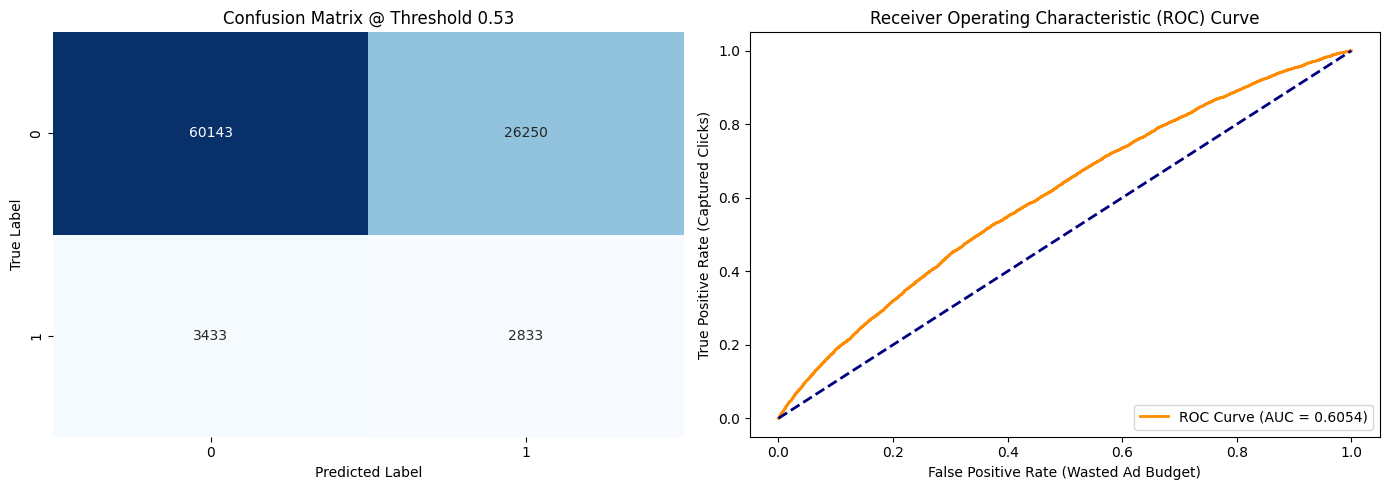

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Confusion Matrix
cm = confusion_matrix(y_val, y_pred_optimal)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title(f'Confusion Matrix @ Threshold {best_threshold:.2f}')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Plot B: ROC Curve
fpr, tpr, _ = roc_curve(y_val, y_probs)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc_score(y_val, y_probs):.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve')
axes[1].set_xlabel('False Positive Rate (Wasted Ad Budget)')
axes[1].set_ylabel('True Positive Rate (Captured Clicks)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

#**PHASE 7: VISUALIZATIONS & FEATURE IMPORTANCE INSIGHTS**

Model Comparison Grouped Bar Chart

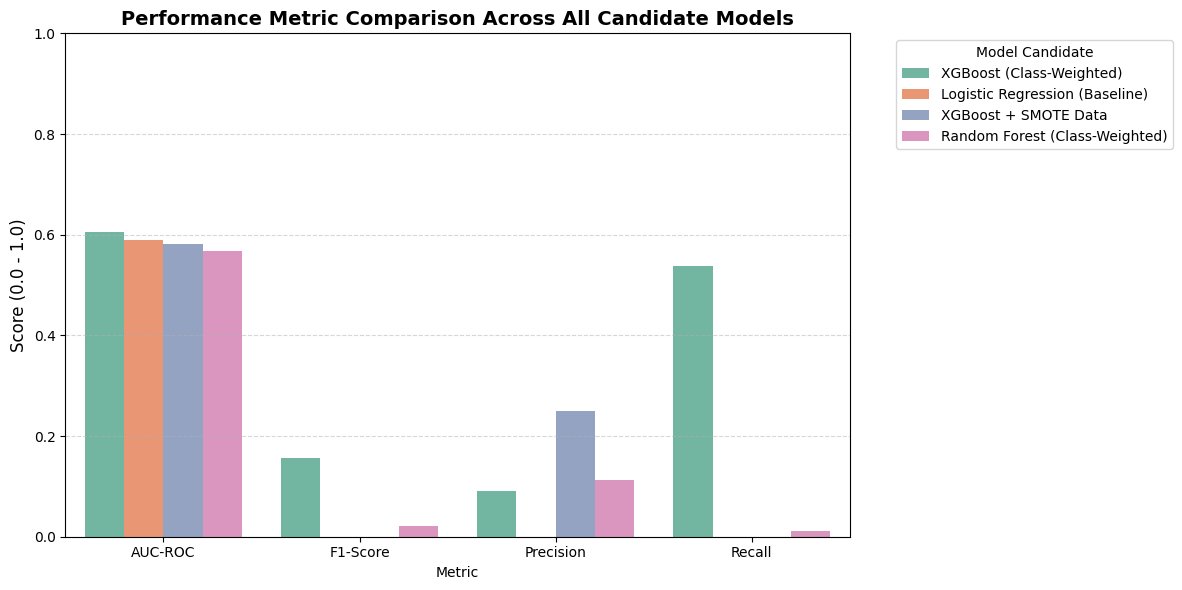

In [ ]:
metrics_to_plot = ['AUC-ROC', 'F1-Score', 'Precision', 'Recall']
df_plot = comparison_df.melt(id_vars=['Model Pipeline'], value_vars=metrics_to_plot,
                             var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 6))
sns.barplot(data=df_plot, x='Metric', y='Score', hue='Model Pipeline', palette='Set2')
plt.title('Performance Metric Comparison Across All Candidate Models', fontsize=14, fontweight='bold')
plt.ylim(0, 1.0)
plt.ylabel('Score (0.0 - 1.0)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Model Candidate', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Top 15 Feature Importance Plot (Best Model: XGBoost Class-Weighted)

/tmp/ipykernel_2219/853831345.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp_df.head(15), x='Importance', y='Feature', palette='viridis')


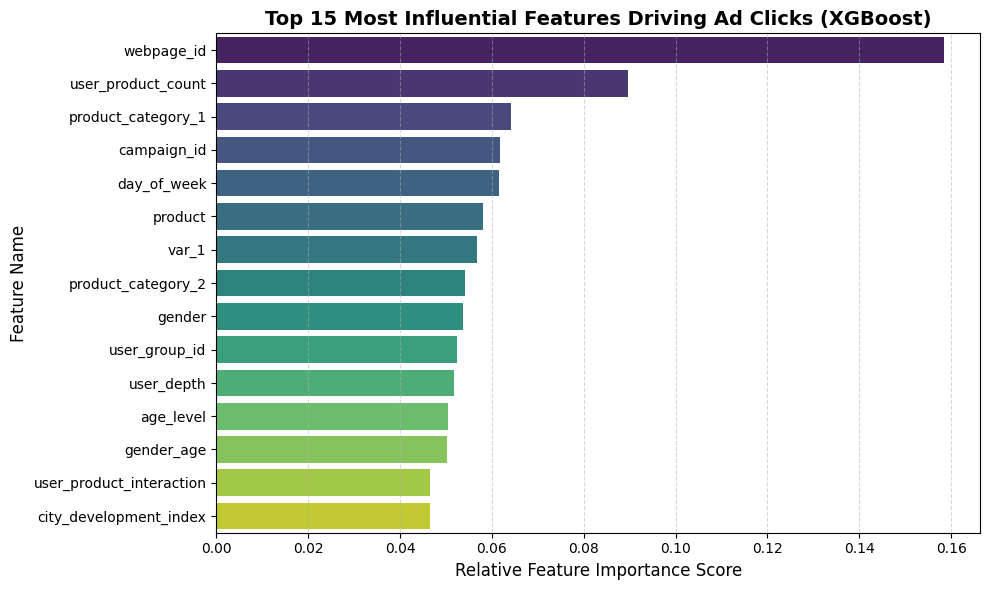

=== TOP 5 DRIVERS OF AD CLICKS ===
-> webpage_id: 0.1583
-> user_product_count: 0.0897
-> product_category_1: 0.0641
-> campaign_id: 0.0619
-> day_of_week: 0.0615


In [ ]:
# Extract feature list directly from X_train DataFrame
feature_names = X_train.columns if hasattr(X_train, 'columns') else df_final.drop(columns=['is_click']).columns

best_xgb = models["XGBoost (Class-Weighted)"]
importances = best_xgb.feature_importances_

# Create DataFrame for Importance Scores
feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('Top 15 Most Influential Features Driving Ad Clicks (XGBoost)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Feature Importance Score', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Print Top 5 Drivers
print("=== TOP 5 DRIVERS OF AD CLICKS ===")
for idx, row in feat_imp_df.head(5).iterrows():
    print(f"-> {row['Feature']}: {row['Importance']:.4f}")